# 🧹 Sprint 2 — Data Preparation
**Entrada:** dataset Kaggle · **Saídas (usadas no Sprint 3):** `data/splits.joblib`, `data/config.joblib`, `models/prep_sparse.joblib`, `models/prep_dense.joblib`

Ordem escolhida para **evitar data leakage**: limpeza (linha-a-linha) → split → TF-IDF / seleção / scaling ajustados **apenas no treino**.

In [1]:
import os, sys, glob, time, warnings, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import joblib
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
for d in ["models", "reports", "data"]:
    os.makedirs(d, exist_ok=True)
sys.path.insert(0, os.path.abspath("src"))   # executar o notebook na raiz do projeto (onde está a pasta src/)

In [3]:
from utils import detect_columns, clean_text, dominant_script, text_features, iqr_bounds, evaluate_model
from data_loader import load_raw

df = load_raw()
df = df.replace({'Portugese': 'Portuguese'})   # correção do rótulo mal escrito no dataset

TEXT_COL, LABEL_COL = "Text", "language"           # ex.: TEXT_COL, LABEL_COL = "Text", "Language"
if TEXT_COL is None or LABEL_COL is None:
    TEXT_COL, LABEL_COL = detect_columns(df)
print(f"Texto: {TEXT_COL!r} | Rótulo: {LABEL_COL!r}")
print("Idiomas:", sorted(df[LABEL_COL].astype(str).unique()))

from data_contract import build_contract
CONTRACT = build_contract(TEXT_COL, LABEL_COL, df[LABEL_COL].nunique())

Ficheiros CSV encontrados: ['dataset.csv']
Texto: 'Text' | Rótulo: 'language'
Idiomas: ['Arabic', 'Chinese', 'Dutch', 'English', 'Estonian', 'French', 'Hindi', 'Indonesian', 'Japanese', 'Korean', 'Latin', 'Persian', 'Portuguese', 'Pushto', 'Romanian', 'Russian', 'Spanish', 'Swedish', 'Tamil', 'Thai', 'Turkish', 'Urdu']


## 2.1 Data Cleaning, Missing Values e Duplicados

In [4]:
n0 = len(df)
data = df[[TEXT_COL, LABEL_COL]].copy()
data = data.dropna(subset=[TEXT_COL, LABEL_COL])                       # sem texto ou rótulo não é utilizável
data[TEXT_COL] = data[TEXT_COL].astype(str).map(clean_text)
data[LABEL_COL] = data[LABEL_COL].astype(str).str.strip()
data = data[data[TEXT_COL].str.len() > 0]                              # vazios após limpeza
data = data.drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)  # evita fuga entre train/test
print(f"Linhas: {n0} -> {len(data)} (removidas {n0 - len(data)})")

Linhas: 22000 -> 21857 (removidas 143)


## 2.2 Outliers (comprimento do texto)
**Trade-off:** textos *curtos* são legítimos (e difíceis) em identificação de idioma, por isso **mantemos**. Removemos só textos *extremamente* longos (IQR × 3).

Limite superior (IQR×3): 1199 chars | outliers longos: 223 (1.02%)


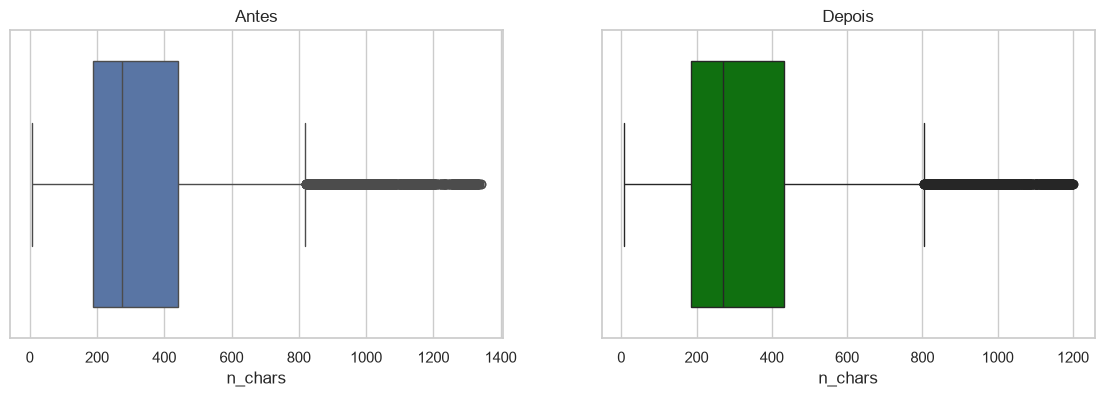

In [5]:
REMOVE_LONG_OUTLIERS = True
data["n_chars"] = data[TEXT_COL].str.len()
lo, hi = iqr_bounds(data["n_chars"], k=3.0)
n_out = (data["n_chars"] > hi).sum()
print(f"Limite superior (IQR×3): {hi:.0f} chars | outliers longos: {n_out} ({n_out / len(data):.2%})")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=data["n_chars"], ax=ax[0]); ax[0].set_title("Antes")
if REMOVE_LONG_OUTLIERS:
    data = data[data["n_chars"] <= hi].reset_index(drop=True)
sns.boxplot(x=data["n_chars"], ax=ax[1], color="green"); ax[1].set_title("Depois"); plt.show()
data = data.drop(columns="n_chars")

MAX_ROWS = 60000     # limite opcional para treinos rápidos
if len(data) > MAX_ROWS:
    from sklearn.model_selection import train_test_split
    data, _ = train_test_split(data, train_size=MAX_ROWS, stratify=data[LABEL_COL], random_state=RANDOM_STATE)
    data = data.reset_index(drop=True); print("Amostra estratificada:", len(data))

## 2.3 Splitting (Train 70% / Validation 15% / Test 15%, estratificado)

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(data[LABEL_COL]); X = data[TEXT_COL].values
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)
N_CLASSES = len(le.classes_)
print(f"train={len(X_train)} | val={len(X_val)} | test={len(X_test)} | classes={N_CLASSES}")

train=15143 | val=3245 | test=3246 | classes=22


## 2.4 Desbalanceamento
Se o rácio max/min > 1.5 usamos `class_weight="balanced"` (simples e sem dados sintéticos, pouco naturais em texto). Alternativas: SMOTE nas features SVD, *undersampling*.

In [7]:
cnt = np.bincount(y_train)
IMB_RATIO = cnt.max() / cnt.min()
CLASS_WEIGHT = "balanced" if IMB_RATIO > 1.5 else None
print(f"Rácio de desbalanceamento (treino): {IMB_RATIO:.2f} -> class_weight={CLASS_WEIGHT}")

Rácio de desbalanceamento (treino): 1.07 -> class_weight=None


## 2.5 Feature Extraction / Engineering / Selection / Scaling
- **Extraction:** TF-IDF de **n-gramas de caracteres** (1–3, `char_wb`): captura a ortografia típica de cada idioma e funciona com textos curtos.
- **Selection:** `SelectKBest(chi2)` mantém as 5000 features mais associadas ao rótulo.
- **Scaling:** `MaxAbsScaler` (mantém esparsidade e não-negatividade, necessário ao Naïve Bayes) nos modelos esparsos; `TruncatedSVD(200)` + `StandardScaler` nos que precisam de features densas.
- Tudo ajustado **só no treino**.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MaxAbsScaler, StandardScaler
from sklearn.decomposition import TruncatedSVD

prep_sparse = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3), sublinear_tf=True, max_features=50000, min_df=2)),
    ("select", SelectKBest(chi2, k=5000)),
    ("scale", MaxAbsScaler()),
])
t0 = time.time(); Xs_train = prep_sparse.fit_transform(X_train, y_train)
print(f"Esparso: {Xs_train.shape} em {time.time()-t0:.1f}s")

prep_dense = Pipeline([("sparse", prep_sparse), ("svd", TruncatedSVD(200, random_state=RANDOM_STATE)), ("scale", StandardScaler())])
t0 = time.time(); prep_dense.fit(X_train, y_train)
print(f"Denso: {prep_dense.transform(X_train[:5]).shape[1]} dimensões em {time.time()-t0:.1f}s")

sel = prep_sparse.named_steps["select"]
names = prep_sparse.named_steps["tfidf"].get_feature_names_out()[sel.get_support()]
print("Top n-gramas (chi2):", [names[i] for i in np.argsort(sel.scores_[sel.get_support()])[::-1][:15]])

Esparso: (15143, 5000) em 16.8s
Denso: 200 dimensões em 17.6s
Top n-gramas (chi2): ['்', 'ı', '，', 'о', 'க', 'ி', 'ă', 'ு', '் ', 'ा', 'த', 'е', 'и', 'ہ', 'а']


## 2.6 Guardar artefactos para o Sprint 3

In [9]:
joblib.dump({"X_train": X_train, "X_val": X_val, "X_test": X_test, "y_train": y_train, "y_val": y_val, "y_test": y_test,
             "label_encoder": le}, "data/splits.joblib")
joblib.dump({"TEXT_COL": TEXT_COL, "LABEL_COL": LABEL_COL, "CONTRACT": CONTRACT, "CLASS_WEIGHT": CLASS_WEIGHT,
             "N_CLASSES": N_CLASSES, "IMB_RATIO": IMB_RATIO}, "data/config.joblib")
joblib.dump(prep_sparse, "models/prep_sparse.joblib"); joblib.dump(prep_dense, "models/prep_dense.joblib")
print(sorted(os.listdir("data")), sorted(os.listdir("models")))

['config.joblib', 'splits.joblib'] ['prep_dense.joblib', 'prep_sparse.joblib']


**Próximo passo:** `03_Sprint3_Modeling.ipynb`.